# Spatial Clustering of Flood Impact in Thailand (2019–2024)
**Group Assignment: Analytics on Complex Data**

Multi-source, spatial data: DDPM flood statistics + HII/ThaiWater rainfall + DOPA population
+ recurrent-flood reference map, joined by **province × year**.

Pipeline: **Data integration → EDA → Preprocessing (missing values, log transform, normalisation, PCA)
→ K-Means vs HDBSCAN → Global Moran's I + LISA hotspots → Evaluation (silhouette + agreement with
the recurrent-flood map)**.

Run `python src/build_dataset.py` first (creates `data/processed/`).

In [1]:
import json
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             f1_score, precision_score, recall_score, silhouette_samples,
                             silhouette_score)
from sklearn.preprocessing import StandardScaler
from libpysal.weights import Queen, attach_islands
from esda.moran import Moran, Moran_Local

warnings.filterwarnings("ignore")
ROOT = Path(".").resolve()
PROC, FIG = ROOT / "data/processed", ROOT / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
SEED = 42
RESULTS = {}


def save(name):
    plt.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Load the integrated data

In [2]:
py = pd.read_csv(PROC / "province_year.csv")
pf = pd.read_csv(PROC / "province_features.csv").set_index("pro_code")
log = json.loads((PROC / "data_log.json").read_text())
geo = gpd.read_file(ROOT / "data/raw/geo/provinces.geojson")
geo["pro_code"] = geo["pro_code"].astype(int)
geo = geo.set_index("pro_code").loc[pf.index]
print("province-year table:", py.shape, "| province table:", pf.shape)
print(json.dumps(log["ddpm_meta"], indent=1, ensure_ascii=False))

province-year table: (462, 25) | province table: (77, 33)
{
 "2562": {
  "rows": 61,
  "dropped_total_rows": 1,
  "level": "province"
 },
 "2563": {
  "rows": 1761,
  "dropped_total_rows": 66,
  "level": "district-event"
 },
 "2564": {
  "rows": 2837,
  "dropped_total_rows": 75,
  "level": "district-event"
 },
 "2565": {
  "rows": 4430,
  "dropped_total_rows": 1,
  "level": "district-event"
 },
 "2566": {
  "rows": 74,
  "dropped_total_rows": 1,
  "level": "province"
 },
 "2567": {
  "rows": 34881,
  "dropped_total_rows": 0,
  "level": "village"
 }
}


## 2. Complex data exploration (EDA)
### 2.1 Raw DDPM attributes are extremely right-skewed
The 2019 file alone has 49 damage attributes; most are zero for most provinces and huge for a few.

48 attributes | median skewness = 5.3 | attributes with skew > 2: 43 | median share of zeros = 82%


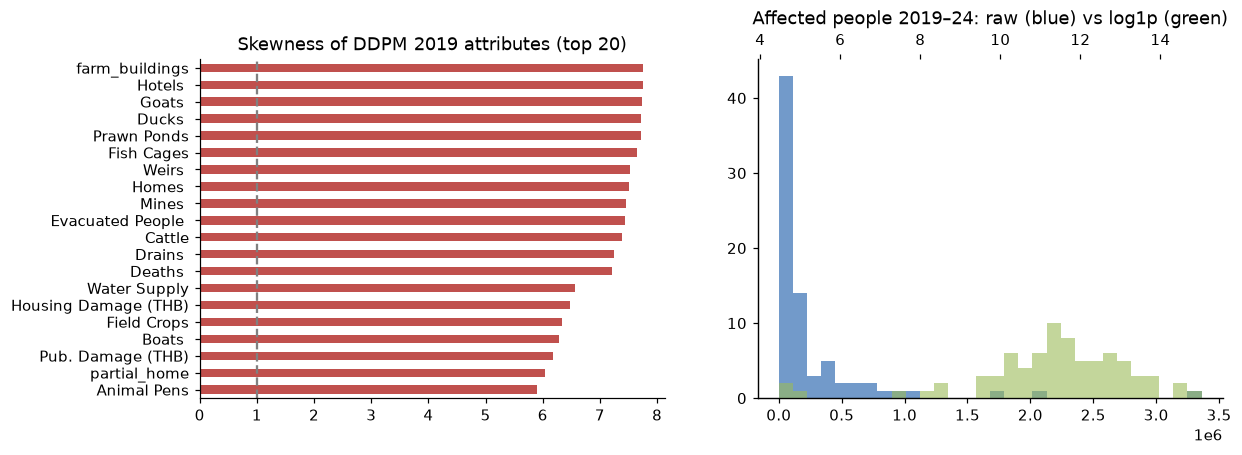

In [3]:
raw19 = pd.read_excel(ROOT / "data/raw/ddpm/2562.xlsx", sheet_name="flood2562cut", header=0).iloc[1:-1]
raw19 = raw19.drop(columns=["Province"]).apply(pd.to_numeric, errors="coerce")
sk = raw19.skew().dropna().sort_values(ascending=False)
zero_share = (raw19 == 0).mean()
print(f"{len(raw19.columns)} attributes | median skewness = {sk.median():.1f} | "
      f"attributes with skew > 2: {(sk > 2).sum()} | median share of zeros = {zero_share.median():.0%}")
RESULTS["eda_raw_attributes"] = int(len(raw19.columns))
RESULTS["eda_median_skew"] = round(float(sk.median()), 2)
RESULTS["eda_skew_gt2"] = int((sk > 2).sum())
RESULTS["eda_median_zero_share"] = round(float(zero_share.median()), 2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sk.head(20)[::-1].plot.barh(ax=ax[0], color="#c0504d")
ax[0].set_title("Skewness of DDPM 2019 attributes (top 20)")
ax[0].axvline(1, ls="--", c="grey")
x = pf["tot_affected_people"]
ax[1].hist(x, bins=30, color="#4f81bd", alpha=.8, label="raw")
ax2 = ax[1].twiny()
ax2.hist(np.log1p(x), bins=30, color="#9bbb59", alpha=.6, label="log1p")
ax[1].set_title("Affected people 2019–24: raw (blue) vs log1p (green)")
save("eda_skew")

### 2.2 Temporal view – flood impact differs strongly by year

      provinces_flooded  affected_people  villages  deaths      rain_mm
year                                                                   
2019                 60        1954287.0   14126.0    30.0  1279.182520
2020                 65        3576470.0   22692.0    33.0  1465.338733
2021                 74        2520791.0   37895.0    67.0  1672.703011
2022                 76        8168028.0   92197.0   158.0  1956.687712
2023                 73        1128588.0   21090.0    42.0  1380.998321
2024                 72        3752172.0   34881.0    78.0  1635.328469


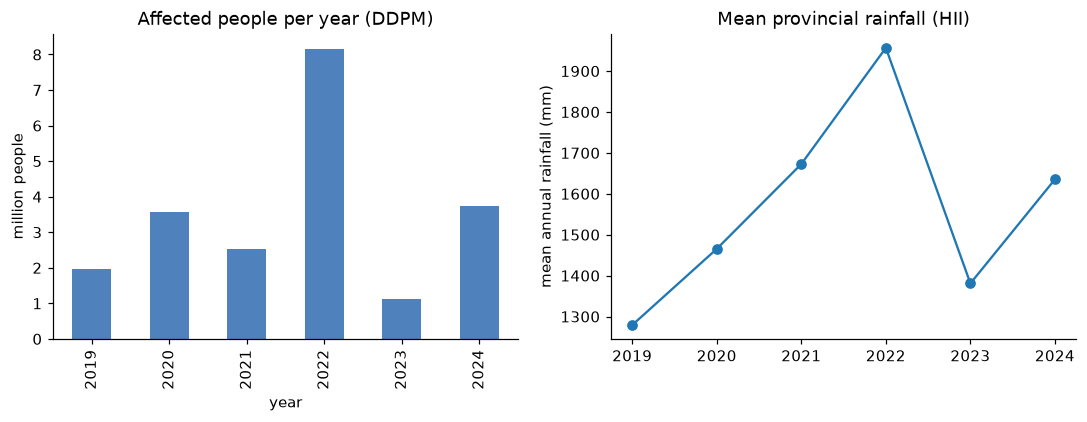

In [4]:
yr = py.groupby("year").agg(provinces_flooded=("flood_reported", "sum"),
                            affected_people=("affected_people", "sum"),
                            villages=("n_villages", "sum"),
                            deaths=("deaths", "sum"),
                            rain_mm=("rain_annual_mm", "mean"))
print(yr)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
(yr["affected_people"] / 1e6).plot.bar(ax=ax[0], color="#4f81bd")
ax[0].set_ylabel("million people"); ax[0].set_title("Affected people per year (DDPM)")
ax[1].plot(yr.index, yr["rain_mm"], marker="o", c="#1f77b4")
ax[1].set_ylabel("mean annual rainfall (mm)"); ax[1].set_title("Mean provincial rainfall (HII)")
save("eda_years")

### 2.3 Spatial view – choropleth maps

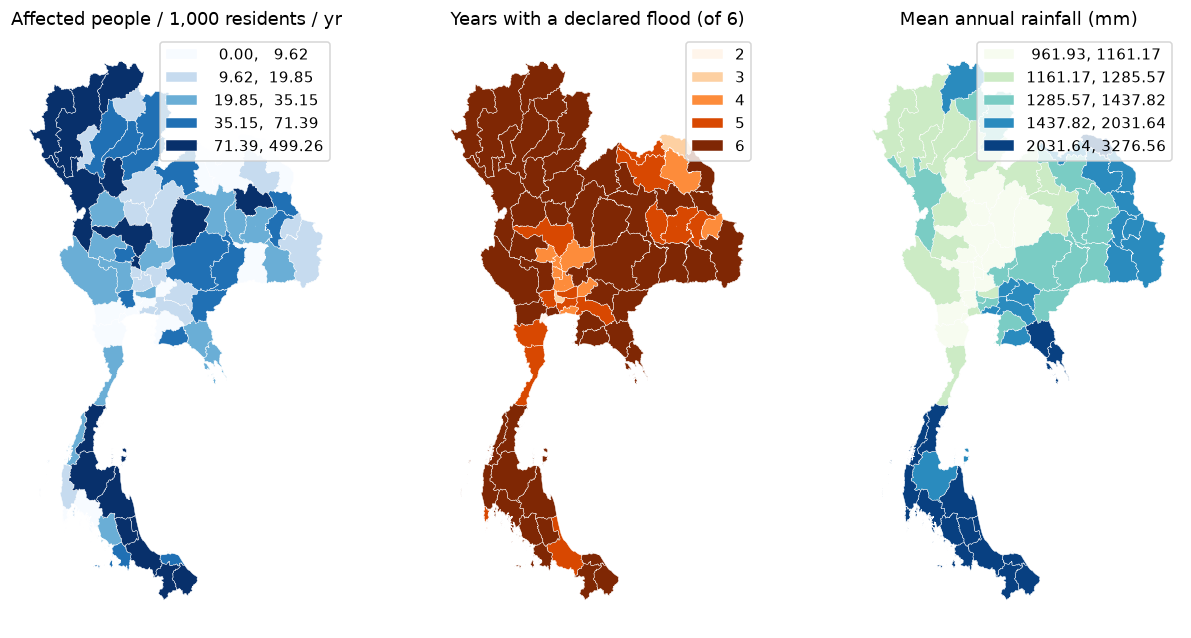

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 7))
geo.assign(v=pf["affected_people_per_1k"]).plot("v", cmap="Blues", legend=True, ax=ax[0],
                                                 scheme="quantiles", k=5, edgecolor="white", lw=.3)
ax[0].set_title("Affected people / 1,000 residents / yr")
geo.assign(v=pf["years_flooded"]).plot("v", cmap="Oranges", legend=True, categorical=True, ax=ax[1],
                                       edgecolor="white", lw=.3)
ax[1].set_title("Years with a declared flood (of 6)")
geo.assign(v=pf["rain_annual_mm"]).plot("v", cmap="GnBu", legend=True, ax=ax[2], scheme="quantiles",
                                        k=5, edgecolor="white", lw=.3)
ax[2].set_title("Mean annual rainfall (mm)")
for a in ax:
    a.set_axis_off()
save("eda_maps")

### 2.4 Correlation among candidate features

      evacuated  livestock
year                      
2019     8179.0    15042.0
2020     1228.0  1547178.0
2021    20866.0   109138.0
2022    46344.0   716852.0
2023       20.0   122055.0
2024      949.0    99502.0


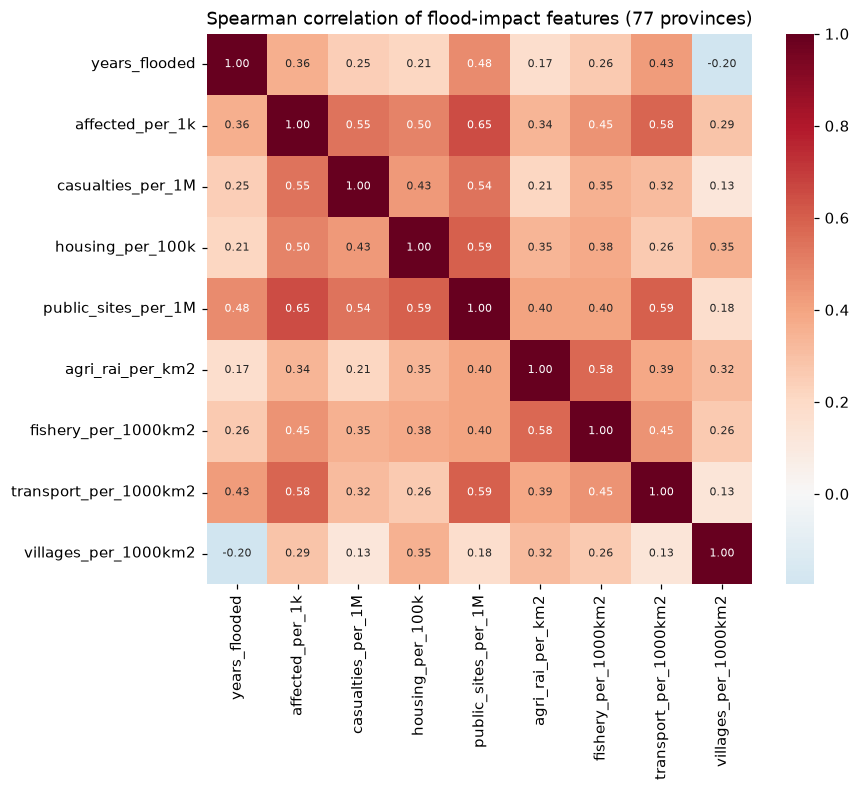

In [6]:
# Features are built from 6-year totals and normalised by population or land area,
# in units chosen so that typical values are > 1 (log1p then really compresses the tail).
A, POP = pf["area_sqkm"], pf["pop_mean"]
F = pd.DataFrame({
    "years_flooded": pf["years_flooded"],                                        # frequency
    "affected_per_1k": 1000 * pf["tot_affected_people"] / 6 / POP,               # human exposure
    "casualties_per_1M": 1e6 * (pf["tot_deaths"] + pf["tot_injured_missing"]) / 6 / POP,
    "housing_per_100k": 1e5 * pf["tot_housing"] / 6 / POP,                       # residential damage
    "public_sites_per_1M": 1e6 * pf["tot_public_sites"] / 6 / POP,               # public infrastructure
    "agri_rai_per_km2": pf["tot_agri_rai"] / 6 / A,                              # farmland damage density
    "fishery_per_1000km2": 1000 * pf["tot_fishery"] / 6 / A,
    "transport_per_1000km2": 1000 * pf["tot_transport"] / 6 / A,                 # roads & bridges
    "villages_per_1000km2": 1000 * pf["tot_n_villages"] / 6 / A,                 # spatial extent
}, index=pf.index)
FEATURES = list(F.columns)
pf = pf.join(F.add_prefix("f_"))
# Dropped on purpose (data-quality decisions):
#  * evacuated  – the 2023/2024 schema barely records it (20 and 949 people nationally vs 46k in 2022)
#  * livestock  – dominated by a few poultry events (skew 8.5 raw / 4.7 after log), mostly zeros
print(py.groupby("year")[["evacuated", "livestock"]].sum())
corr = np.log1p(F).corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation of flood-impact features (77 provinces)")
save("eda_corr")

## 3. Complex data pre-processing
Already done in `src/build_dataset.py` (see data_log):
* **Integration** of 4 agencies: different file formats (xlsx with 1–3 header rows, HTML disguised as .xls,
  CSV with merged cells), different granularity (province / district-event / village), joined by a
  normalised province code (names such as "จ.กรุงเทพมหานคร", "จังหวัดสมุทรปราการ", "กรุงเทพฯ").
* **Schema harmonisation**: 6 yearly schemas (44–66 columns) → 13 common attributes.
* **Removing subtotal/grand-total rows** embedded in the data ("X รวม", "รวมทั้งหมด 73 จังหวัด").
* **Zeros that mean missing**: households > 0 but people = 0 → imputed with the median people/household ratio.
* **Normalisation by population / area** so big provinces are not automatically "worse".

Here: **log1p transform** (skew) → **z-score standardisation** → **PCA**.

{
 "imputed_people_from_households": 8,
 "median_people_per_household": 2.742698882505046,
 "province_years_reported": 420,
 "rain_inconsistent_rows": {
  "2026": 539
 }
}
                       skew_raw  skew_log1p
years_flooded             -1.72       -2.24
affected_per_1k            3.27       -0.32
casualties_per_1M          2.75        0.81
housing_per_100k           2.37       -0.70
public_sites_per_1M        6.28        0.17
agri_rai_per_km2           2.88        0.67
fishery_per_1000km2        3.73        0.15
transport_per_1000km2      3.42        0.09
villages_per_1000km2       2.15       -0.71
Components for >=80% variance: 5  (cum = 84.9%)


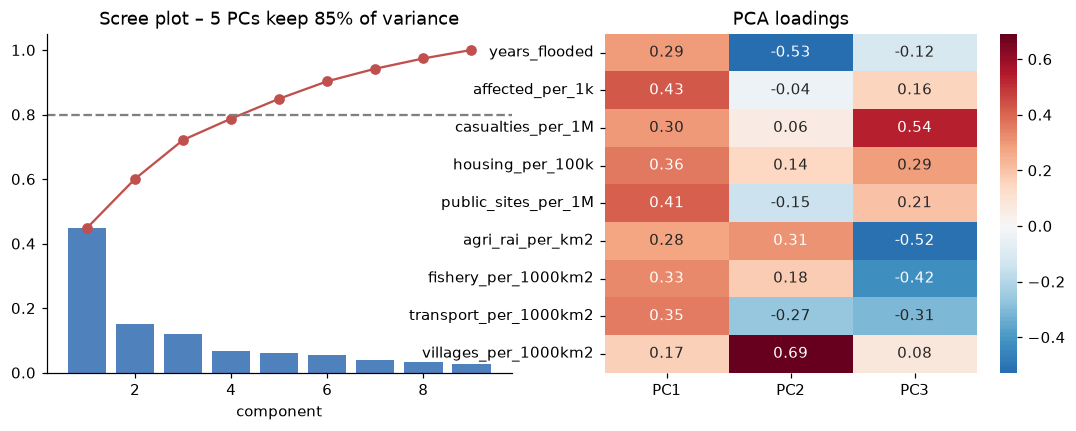

In [7]:
print(json.dumps({k: log[k] for k in ["imputed_people_from_households", "median_people_per_household",
                                      "province_years_reported", "rain_inconsistent_rows"]}, indent=1))
X_raw = F.copy()
X_log = np.log1p(X_raw)
skew_before, skew_after = X_raw.skew(), X_log.skew()
print(pd.DataFrame({"skew_raw": skew_before, "skew_log1p": skew_after}).round(2))
RESULTS["skew_raw_median"] = round(float(skew_before.median()), 2)
RESULTS["skew_log_median"] = round(float(skew_after.median()), 2)

Z = StandardScaler().fit_transform(X_log)
pca = PCA(random_state=SEED).fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
n_pc = int(np.argmax(cum >= 0.80) + 1)
print(f"Components for >=80% variance: {n_pc}  (cum = {cum[n_pc-1]:.1%})")
RESULTS["pca_n_components"] = n_pc
RESULTS["pca_cum_var"] = round(float(cum[n_pc - 1]), 3)
RESULTS["pca_pc1_var"] = round(float(pca.explained_variance_ratio_[0]), 3)
P = pca.transform(Z)[:, :n_pc]

loadings = pd.DataFrame(pca.components_[:3].T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(cum) + 1), pca.explained_variance_ratio_, color="#4f81bd")
ax[0].plot(range(1, len(cum) + 1), cum, "o-", c="#c0504d")
ax[0].axhline(.80, ls="--", c="grey"); ax[0].set_xlabel("component")
ax[0].set_title(f"Scree plot – {n_pc} PCs keep {cum[n_pc-1]:.0%} of variance")
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1])
ax[1].set_title("PCA loadings")
save("pca")

# Flood Severity Index = PC1 score (sign fixed so that higher = more impact)
sign = np.sign(loadings["PC1"].sum())
pf["severity_index"] = sign * pca.transform(Z)[:, 0]

## 4. Analytics technique 1 – Clustering: K-Means (covered in class) vs **HDBSCAN** (not covered)
### 4.1 K-Means: choose k with elbow + silhouette

      wcss  silhouette  davies_bouldin  smallest_cluster  seed_stability_ari
k                                                                           
2  390.512       0.307           1.229                24               0.981
3  317.955       0.217           1.433                14               0.886
4  272.631       0.223           1.323                10               0.800
5  243.916       0.200           1.325                 4               0.633
6  213.764       0.226           1.179                 3               0.661
7  193.687       0.202           1.224                 3               0.692
8  175.674       0.225           1.186                 3               0.670


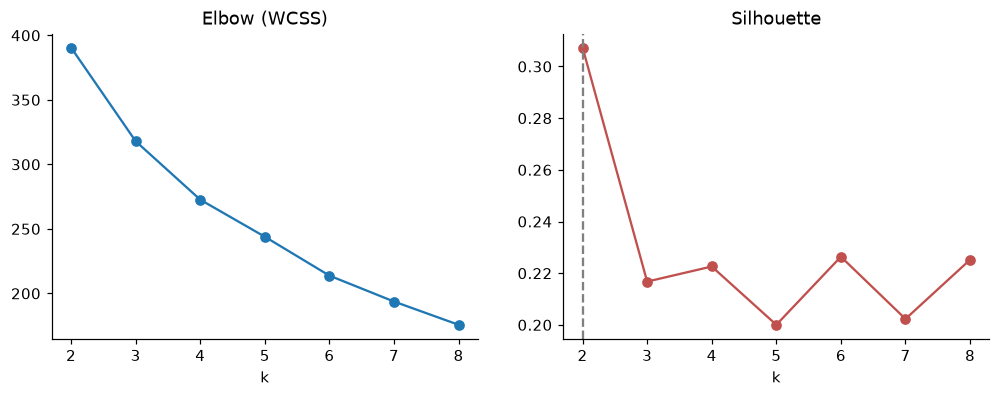

In [8]:
ks = range(2, 9)
km_rows = []
for k in ks:
    km = KMeans(k, n_init=50, random_state=SEED).fit(P)
    km_rows.append({"k": k, "wcss": km.inertia_, "silhouette": silhouette_score(P, km.labels_),
                    "davies_bouldin": davies_bouldin_score(P, km.labels_),
                    "smallest_cluster": int(np.bincount(km.labels_).min()),
                    # stability: agreement of 20 re-runs with different random seeds
                    "seed_stability_ari": np.mean([adjusted_rand_score(
                        km.labels_, KMeans(k, n_init=10, random_state=s).fit(P).labels_) for s in range(20)])})
km_tab = pd.DataFrame(km_rows).set_index("k")
print(km_tab.round(3))
k_best = int(km_tab["silhouette"].idxmax())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(km_tab.index, km_tab.wcss, "o-"); ax[0].set_title("Elbow (WCSS)"); ax[0].set_xlabel("k")
ax[1].plot(km_tab.index, km_tab.silhouette, "o-", c="#c0504d"); ax[1].set_title("Silhouette")
ax[1].axvline(k_best, ls="--", c="grey"); ax[1].set_xlabel("k")
save("kmeans_k")

Silhouette peaks at k = 2, which is only a "more / less flooded" split. Silhouettes for k = 3…8 are
almost equal (≈0.20–0.23), so we add a **stability** criterion: pick the best silhouette among k ≥ 3
with smallest cluster ≥ 3 provinces **and** seed-stability ARI ≥ 0.75.

In [9]:
ok = km_tab.loc[3:].query("smallest_cluster >= 3 and seed_stability_ari >= 0.75")
k_use = int(ok["silhouette"].idxmax())
km = KMeans(k_use, n_init=50, random_state=SEED).fit(P)
# order clusters by mean severity: 0 = lowest impact
order = pd.Series(pf["severity_index"].values).groupby(km.labels_).mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
pf["km"] = pd.Series(km.labels_).map(remap).values
RESULTS["kmeans_k_best_silhouette"] = k_best
RESULTS["kmeans_k_used"] = k_use

RESULTS["kmeans_seed_stability_ari"] = round(float(km_tab.loc[k_use, "seed_stability_ari"]), 3)
RESULTS["kmeans_table"] = km_tab.round(3).reset_index().to_dict(orient="records")
print(f"k used = {k_use}; seed-stability ARI = {km_tab.loc[k_use, 'seed_stability_ari']:.3f}")

k used = 4; seed-stability ARI = 0.800


### 4.2 HDBSCAN – density-based, finds k automatically and labels outliers as noise
Tune `min_cluster_size`; silhouette is computed on non-noise points.

In [10]:
hd_rows = []
for mcs in range(3, 13):
    for ms in [None, 2, 3]:
        lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms, copy=True).fit_predict(P)
        mask = lab >= 0
        n_cl = len(set(lab[mask]))
        sil = silhouette_score(P[mask], lab[mask]) if n_cl >= 2 else np.nan
        hd_rows.append({"min_cluster_size": mcs, "min_samples": ms or mcs, "n_clusters": n_cl,
                        "noise": int((~mask).sum()), "silhouette_non_noise": sil})
hd_tab = pd.DataFrame(hd_rows)
print(hd_tab.dropna().sort_values("silhouette_non_noise", ascending=False).head(10).round(3))
# choose: highest silhouette with >= 2 clusters and noise <= 25% of provinces
cand = hd_tab[(hd_tab.n_clusters >= 2) & (hd_tab.noise <= 0.25 * len(P))].dropna()
best = cand.sort_values(["silhouette_non_noise", "noise"], ascending=[False, True]).iloc[0]
hd = HDBSCAN(min_cluster_size=int(best.min_cluster_size), min_samples=int(best.min_samples), copy=True).fit(P)
lab = hd.labels_
order = pd.Series(pf["severity_index"].values[lab >= 0]).groupby(lab[lab >= 0]).mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
pf["hd"] = [remap.get(l, -1) for l in lab]
pf["hd_prob"] = hd.probabilities_
RESULTS["hdbscan_params"] = {"min_cluster_size": int(best.min_cluster_size), "min_samples": int(best.min_samples)}
RESULTS["hdbscan_n_clusters"] = int(best.n_clusters)
RESULTS["hdbscan_noise"] = int(best.noise)
print(RESULTS["hdbscan_params"], "clusters:", int(best.n_clusters), "noise:", int(best.noise))

    min_cluster_size  min_samples  n_clusters  noise  silhouette_non_noise
1                  3            2           2      3                 0.473
6                  5            5           2     57                 0.366
3                  4            4           2     47                 0.327
28                12            2           2     33                 0.326
25                11            2           2     33                 0.326
22                10            2           2     33                 0.326
19                 9            2           2     33                 0.326
13                 7            2           2     33                 0.326
16                 8            2           2     33                 0.326
4                  4            2           2     22                 0.310
{'min_cluster_size': 3, 'min_samples': 2} clusters: 2 noise: 3


### 4.3 Cluster profiles (interpretability)

km                             0        1        2        3
n_provinces                10.00    24.00    16.00    27.00
f_years_flooded             4.00     6.00     6.00     6.00
f_affected_per_1k           3.29    13.32    70.72    35.21
f_casualties_per_1M         0.00     0.27     2.28     1.03
f_housing_per_100k          9.39    80.72   367.65   310.49
f_public_sites_per_1M       0.54     6.57    53.08    21.62
f_agri_rai_per_km2          0.04     0.88     0.96    10.15
f_fishery_per_1000km2       0.00     5.17    14.90    70.28
f_transport_per_1000km2     1.58     6.96    14.26    14.36
f_villages_per_1000km2     92.59    42.89    55.12    93.82
rain_annual_mm           1559.59  1466.54  1277.73  1244.49
rain_max_month_mm         415.32   366.01   350.21   310.33
rain_anomaly_pct           -2.30    -4.07    -0.06    -2.22
severity_index             -3.00    -0.75     1.33     1.40
K0: Phra Nakhon Si Ayutthaya, Pathum Thani, Phuket, Sakon Nakhon, Amnat Charoen, Nakhon Nayok, Nong 

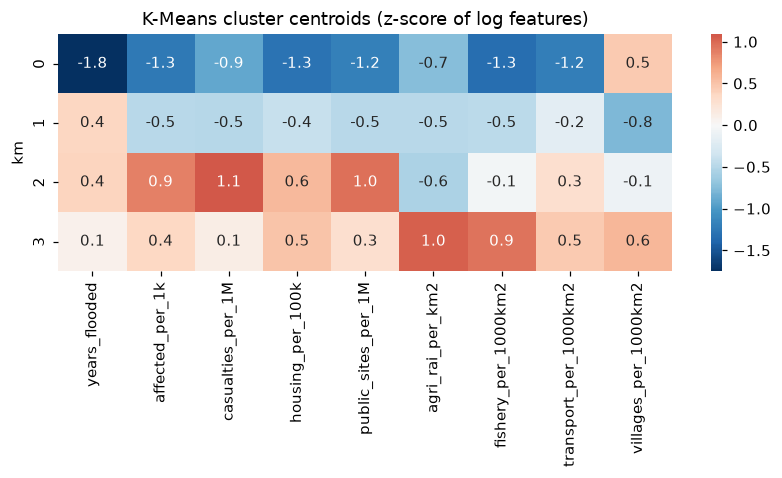

In [11]:
prof_cols = ["f_" + c for c in FEATURES] + ["rain_annual_mm", "rain_max_month_mm", "rain_anomaly_pct", "severity_index"]
prof = pf.groupby("km")[prof_cols].median().round(2)
prof.insert(0, "n_provinces", pf.groupby("km").size())
print(prof.T)
for c in sorted(pf.km.unique()):
    print(f"K{c}:", ", ".join(pf.loc[pf.km == c].sort_values("severity_index", ascending=False)["pro_en"].head(10)))
print("HDBSCAN noise provinces:", ", ".join(pf.loc[pf.hd == -1, "pro_en"]))
# descriptive names (assigned from the profile, not by hand)
sev_rank = prof["severity_index"].sort_values().index.tolist()
top2 = sev_rank[-2:]
agri_c = max(top2, key=lambda c: prof.loc[c, "f_agri_rai_per_km2"])
flash_c = [c for c in top2 if c != agri_c][0]
NAMES = {sev_rank[0]: "Low reported impact", agri_c: "Agricultural basin flooding",
         flash_c: "Flash-flood / human impact"}
for c in sev_rank[1:-2]:
    NAMES[c] = "Moderate impact"
pf["km_name"] = pf["km"].map(NAMES)
prof.insert(0, "name", pd.Series(NAMES))
print(prof[["name", "n_provinces"]])
RESULTS["kmeans_names"] = {int(k): v for k, v in NAMES.items()}
prof.to_csv(FIG / "kmeans_profile.csv")
RESULTS["kmeans_profile"] = prof.reset_index().to_dict(orient="records")
RESULTS["hdbscan_noise_provinces"] = pf.loc[pf.hd == -1, "pro_en"].tolist()

zprof = pd.DataFrame(Z, columns=FEATURES, index=pf.index).groupby(pf["km"]).mean()
plt.figure(figsize=(9, 2.8))
sns.heatmap(zprof, cmap="RdBu_r", center=0, annot=True, fmt=".1f")
plt.title("K-Means cluster centroids (z-score of log features)")
save("kmeans_profile")

### 4.4 Compare clusterings in PCA space and on the map

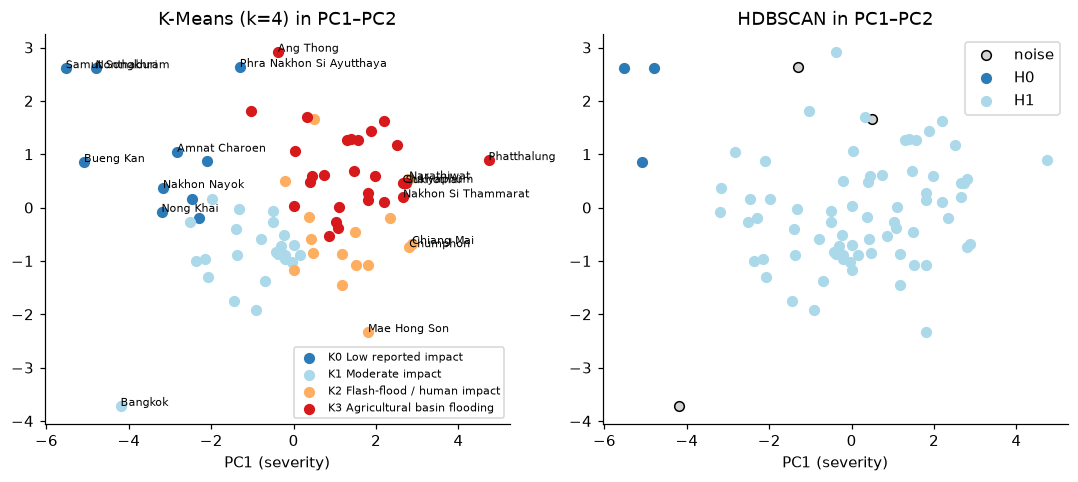

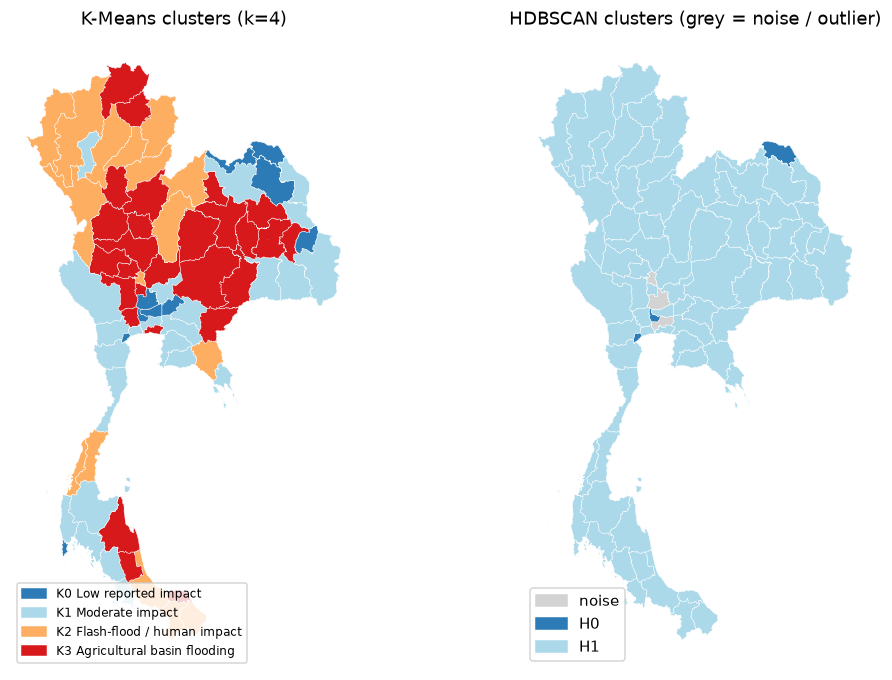

In [12]:
pal = ["#2c7bb6", "#abd9e9", "#fdae61", "#d7191c", "#7b3294", "#008837"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for c in sorted(pf["km"].unique()):
    m = pf["km"].values == c
    ax[0].scatter(P[m, 0] * sign, P[m, 1], s=40, color=pal[c], label=f"K{c} {NAMES[c]}")
ax[0].set_title(f"K-Means (k={k_use}) in PC1–PC2"); ax[0].legend(fontsize=7); ax[0].set_xlabel("PC1 (severity)")
for c in sorted(pf["hd"].unique()):
    m = pf["hd"].values == c
    ax[1].scatter(P[m, 0] * sign, P[m, 1], s=40, color="lightgrey" if c < 0 else pal[c],
                  edgecolor="k" if c < 0 else None, label="noise" if c < 0 else f"H{c}")
ax[1].set_title("HDBSCAN in PC1–PC2"); ax[1].legend(); ax[1].set_xlabel("PC1 (severity)")
for i, name in enumerate(pf["pro_en"]):
    if abs(P[i, 0]) > 2.6 or abs(P[i, 1]) > 2.2:
        ax[0].annotate(name, (P[i, 0] * sign, P[i, 1]), fontsize=7)
save("clusters_pca")

fig, ax = plt.subplots(1, 2, figsize=(11, 7.5))
cm_k = {c: pal[c] for c in range(k_use)}
geo.assign(c=pf["km"].map(cm_k)).plot(color=geo.assign(c=pf["km"].map(cm_k))["c"], ax=ax[0], edgecolor="white", lw=.3)
ax[0].set_title(f"K-Means clusters (k={k_use})")
cols_h = pf["hd"].map(lambda c: "lightgrey" if c < 0 else pal[c])
geo.plot(color=cols_h, ax=ax[1], edgecolor="white", lw=.3)
ax[1].set_title("HDBSCAN clusters (grey = noise / outlier)")
for a in ax:
    a.set_axis_off()
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=pal[c], label=f"K{c} {NAMES[c]}") for c in range(k_use)], loc="lower left", fontsize=8)
ax[1].legend(handles=[Patch(color="lightgrey", label="noise")] +
             [Patch(color=pal[c], label=f"H{c}") for c in sorted(set(pf.hd) - {-1})], loc="lower left")
save("clusters_map")

## 5. Analytics technique 2 – Spatial autocorrelation: **Global Moran's I** and **LISA** (not covered in class)
Spatial weights: Queen contiguity (provinces sharing a border). Phuket is an island, so it is attached
to its nearest neighbour. Weights are row-standardised; inference with 9,999 permutations.

In [13]:
from libpysal.weights import KNN

gdf = geo.reset_index()
w = Queen.from_dataframe(gdf, use_index=False)
print("islands before fix:", [gdf.pro_en[i] for i in w.islands])
if w.islands:
    w = attach_islands(w, KNN.from_dataframe(gdf.to_crs(32647), k=1))
w.transform = "r"
print("islands after fix:", w.islands, "| mean neighbours:", round(w.mean_neighbors, 2))

y = pf["severity_index"].values
mi = Moran(y, w, permutations=9999)
print(f"Global Moran's I (severity index) = {mi.I:.3f}, E[I] = {mi.EI:.3f}, z = {mi.z_sim:.2f}, p = {mi.p_sim:.4f}")
RESULTS["moran_I"] = round(float(mi.I), 3)
RESULTS["moran_p"] = float(mi.p_sim)
RESULTS["moran_z"] = round(float(mi.z_sim), 2)

# Moran's I per year: is the clustering of impact stable over time?
mi_year = {}
for yv, d in py.groupby("year"):
    v = np.log1p(1000 * d.set_index("pro_code").loc[pf.index, "affected_people"] /
                 d.set_index("pro_code").loc[pf.index, "population"]).values
    m = Moran(v, w, permutations=9999)
    mi_year[int(yv)] = {"I": round(float(m.I), 3), "p": float(m.p_sim)}
print(pd.DataFrame(mi_year).T)
RESULTS["moran_by_year"] = mi_year

islands before fix: []
islands after fix: [] | mean neighbours: 4.6
Global Moran's I (severity index) = 0.438, E[I] = -0.013, z = 5.84, p = 0.0001


          I       p
2019  0.279  0.0004
2020  0.397  0.0001
2021  0.421  0.0001
2022  0.331  0.0001
2023  0.255  0.0012
2024  0.419  0.0001


lisa
not significant    53
LL (coldspot)      12
HH (hotspot)        9
LH                  2
HL                  1
Name: count, dtype: int64
Hotspots: Lampang, Uttaradit, Phrae, Phayao, Chiang Rai, Kamphaeng Phet, Tak, Sukhothai, Phetchabun
Coldspots: Bangkok, Samut Prakan, Pathum Thani, Chachoengsao, Bueng Kan, Nong Khai, Sakon Nakhon, Nakhon Phanom, Ratchaburi, Samut Sakhon, Samut Songkhram, Phetchaburi


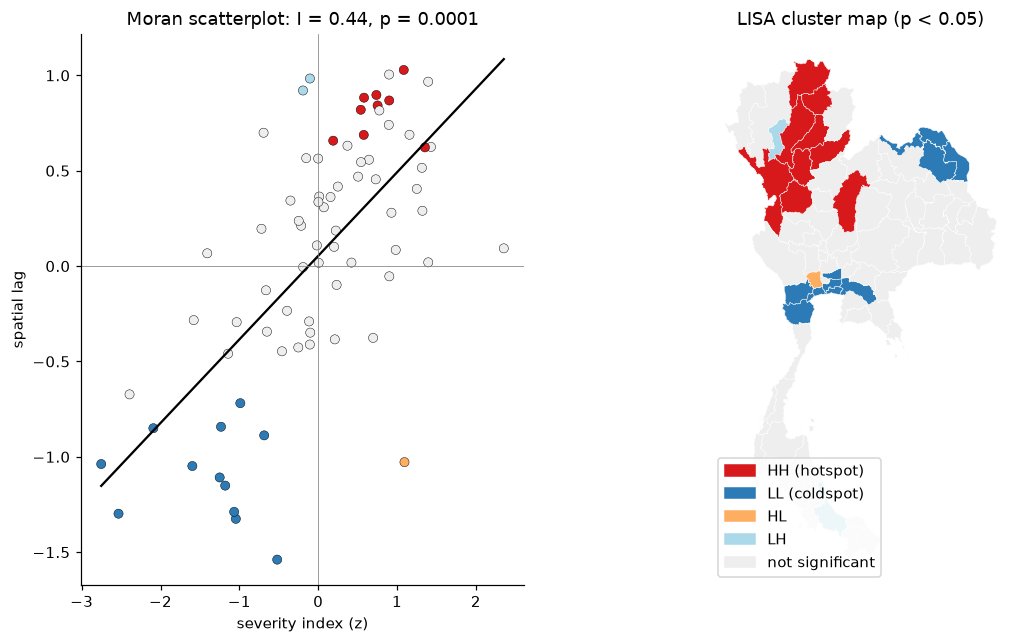

In [14]:
lisa = Moran_Local(y, w, permutations=9999, seed=SEED)
quad = {1: "HH (hotspot)", 2: "LH", 3: "LL (coldspot)", 4: "HL"}
pf["lisa"] = [quad[q] if p < 0.05 else "not significant" for q, p in zip(lisa.q, lisa.p_sim)]
print(pf["lisa"].value_counts())
print("Hotspots:", ", ".join(pf.loc[pf.lisa == "HH (hotspot)", "pro_en"]))
print("Coldspots:", ", ".join(pf.loc[pf.lisa == "LL (coldspot)", "pro_en"]))
RESULTS["lisa_counts"] = pf["lisa"].value_counts().to_dict()
RESULTS["lisa_hotspots"] = pf.loc[pf.lisa == "HH (hotspot)", "pro_en"].tolist()
RESULTS["lisa_coldspots"] = pf.loc[pf.lisa == "LL (coldspot)", "pro_en"].tolist()

lcol = {"HH (hotspot)": "#d7191c", "LL (coldspot)": "#2c7bb6", "HL": "#fdae61", "LH": "#abd9e9",
        "not significant": "#eeeeee"}
fig, ax = plt.subplots(1, 2, figsize=(12, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
lag = w.sparse @ ((y - y.mean()) / y.std())
zy = (y - y.mean()) / y.std()
ax[0].scatter(zy, lag, c=[lcol[l] for l in pf.lisa], edgecolor="k", lw=.3)
b = np.polyfit(zy, lag, 1)
xx = np.linspace(zy.min(), zy.max(), 10)
ax[0].plot(xx, b[0] * xx + b[1], c="k")
ax[0].axhline(0, c="grey", lw=.5); ax[0].axvline(0, c="grey", lw=.5)
ax[0].set_xlabel("severity index (z)"); ax[0].set_ylabel("spatial lag")
ax[0].set_title(f"Moran scatterplot: I = {mi.I:.2f}, p = {mi.p_sim:.4f}")
geo.plot(color=pf["lisa"].map(lcol), ax=ax[1], edgecolor="white", lw=.3)
ax[1].legend(handles=[Patch(color=v, label=k) for k, v in lcol.items()], loc="lower left")
ax[1].set_title("LISA cluster map (p < 0.05)"); ax[1].set_axis_off()
save("lisa")

## 6. Evaluation
### 6.1 Internal validity – silhouette, Davies–Bouldin, Calinski–Harabasz

                     clusters  noise  silhouette  davies_bouldin  \
K-Means                   4.0    0.0       0.223           1.323   
HDBSCAN (non-noise)       2.0    3.0       0.473           0.574   

                     calinski_harabasz  
K-Means                         28.177  
HDBSCAN (non-noise)             17.861  


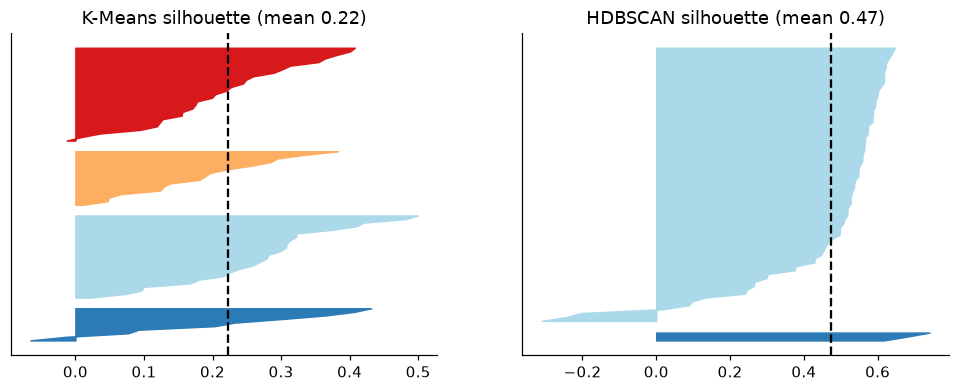

In [15]:
mask = pf["hd"].values >= 0
ev = pd.DataFrame({
    "K-Means": {"clusters": k_use, "noise": 0,
                "silhouette": silhouette_score(P, pf.km), "davies_bouldin": davies_bouldin_score(P, pf.km),
                "calinski_harabasz": calinski_harabasz_score(P, pf.km)},
    "HDBSCAN (non-noise)": {"clusters": RESULTS["hdbscan_n_clusters"], "noise": int((~mask).sum()),
                            "silhouette": silhouette_score(P[mask], pf.hd[mask]),
                            "davies_bouldin": davies_bouldin_score(P[mask], pf.hd[mask]),
                            "calinski_harabasz": calinski_harabasz_score(P[mask], pf.hd[mask])},
}).T
print(ev.round(3))
RESULTS["internal_eval"] = ev.round(3).reset_index().to_dict(orient="records")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, labels, title in [(ax[0], pf.km.values, "K-Means"), (ax[1], pf.hd.values, "HDBSCAN")]:
    m = labels >= 0
    s = silhouette_samples(P[m], labels[m])
    yl = 0
    for c in sorted(set(labels[m])):
        sc = np.sort(s[labels[m] == c])
        a.fill_betweenx(np.arange(yl, yl + len(sc)), 0, sc, color=pal[c])
        yl += len(sc) + 2
    a.axvline(s.mean(), ls="--", c="k"); a.set_title(f"{title} silhouette (mean {s.mean():.2f})"); a.set_yticks([])
save("silhouette")

### 6.2 External validity – agreement with the recurrent-flood reference map
Reference = share of each province's land that flooded ≥ 4 times in 10 years (LDD recurrent-flood
statistics, sub-district level aggregated to province). A province is a **reference "recurrent-flood
province"** if its share is in the top quartile.

Spearman(severity index, recurrent share) = 0.03 (p = 0.7842)
Recurrent share by K-Means cluster (median): {0: 0.017, 1: 0.005, 2: 0.001, 3: 0.016} Kruskal-Wallis p = 0.0158


                                          flagged  precision  recall     f1  \
method                                                                        
K-Means K3 – Agricultural basin flooding       27      0.444    0.60  0.511   
K-Means K2 – Flash-flood / human impact        16      0.062    0.05  0.056   
K-Means both high-impact clusters              43      0.302    0.65  0.413   
HDBSCAN top cluster (H1)                       71      0.239    0.85  0.374   
LISA HH hotspots                                9      0.111    0.05  0.069   
Severity index top quartile                    20      0.250    0.25  0.250   

                                          random_f1  perm_p  
method                                                       
K-Means K3 – Agricultural basin flooding      0.297   0.007  
K-Means K2 – Flash-flood / human impact       0.231   0.999  
K-Means both high-impact clusters             0.353   0.247  
HDBSCAN top cluster (H1)                      0.406   0.9

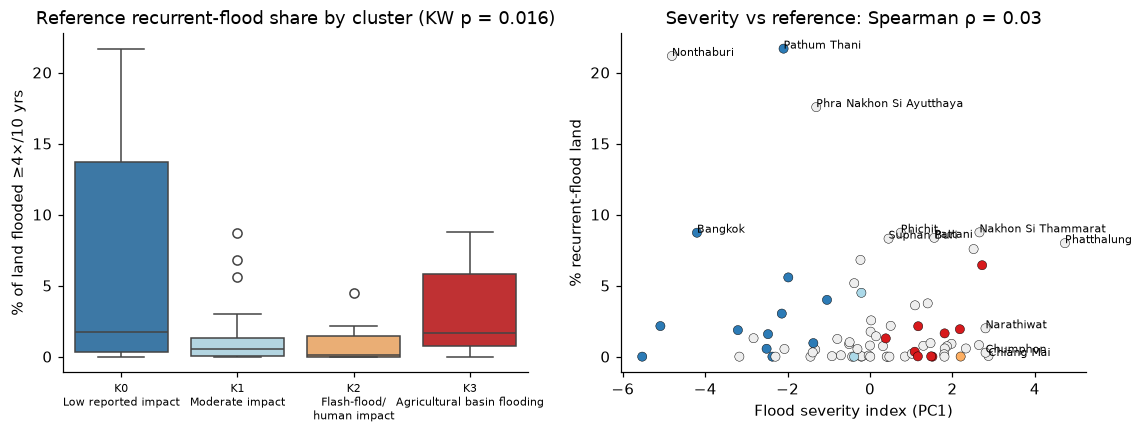

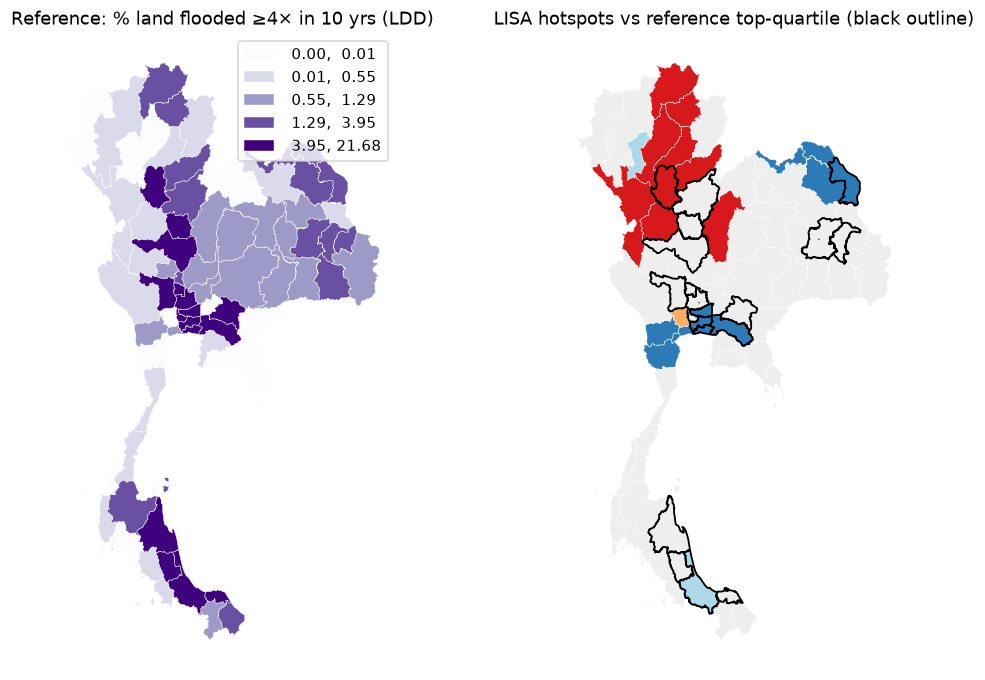

In [16]:
ref = pf["recurrent_share"]
pf["ref_high"] = (ref >= ref.quantile(0.75)).astype(int)
rho, p_rho = stats.spearmanr(pf["severity_index"], ref)
print(f"Spearman(severity index, recurrent share) = {rho:.2f} (p = {p_rho:.4f})")
RESULTS["spearman_severity_ref"] = {"rho": round(float(rho), 3), "p": float(p_rho)}

# recurrent share by cluster + Kruskal-Wallis
kw = stats.kruskal(*[ref[pf.km == c] for c in sorted(pf.km.unique())])
print("Recurrent share by K-Means cluster (median):", ref.groupby(pf.km).median().round(3).to_dict(),
      f"Kruskal-Wallis p = {kw.pvalue:.4f}")
RESULTS["kruskal_km_p"] = float(kw.pvalue)
RESULTS["ref_share_by_km"] = ref.groupby(pf.km).median().round(4).to_dict()


def agree(pred, name):
    return {"method": name, "flagged": int(pred.sum()),
            "precision": precision_score(pf.ref_high, pred, zero_division=0),
            "recall": recall_score(pf.ref_high, pred, zero_division=0),
            "f1": f1_score(pf.ref_high, pred, zero_division=0)}


top_km = agri_c
top_hd = pf.loc[pf.hd >= 0, "hd"].max()
rows = [agree((pf.km == agri_c).astype(int), f"K-Means K{agri_c} – {NAMES[agri_c]}"),
        agree((pf.km == flash_c).astype(int), f"K-Means K{flash_c} – {NAMES[flash_c]}"),
        agree(pf.km.isin(top2).astype(int), "K-Means both high-impact clusters"),
        agree((pf.hd == top_hd).astype(int), f"HDBSCAN top cluster (H{top_hd})"),
        agree((pf.lisa == "HH (hotspot)").astype(int), "LISA HH hotspots"),
        agree((pf.severity_index >= pf.severity_index.quantile(.75)).astype(int), "Severity index top quartile")]
# random baseline for every method: flag the SAME number of provinces at random (2,000 draws)
# -> expected F1 by chance and a permutation p-value
rng = np.random.default_rng(SEED)
for r in rows:
    n = r["flagged"]
    sims = np.array([f1_score(pf.ref_high, rng.permutation(np.r_[np.ones(n), np.zeros(len(pf) - n)]))
                     for _ in range(2000)])
    r["random_f1"] = sims.mean()
    r["perm_p"] = (np.sum(sims >= r["f1"]) + 1) / (len(sims) + 1)
ext = pd.DataFrame(rows).set_index("method")
print(ext.round(3))
RESULTS["external_eval"] = ext.round(3).reset_index().to_dict(orient="records")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=pf.km, y=100 * ref, ax=ax[0], palette=pal[:k_use])
ax[0].set_xticklabels([f"K{c}\n{NAMES[c]}".replace(" / ", "/\n") for c in range(k_use)], fontsize=7); ax[0].set_xlabel(""); ax[0].set_ylabel("% of land flooded ≥4×/10 yrs")
ax[0].set_title(f"Reference recurrent-flood share by cluster (KW p = {kw.pvalue:.3f})")
ax[1].scatter(pf.severity_index, 100 * ref, c=[lcol[l] for l in pf.lisa], edgecolor="k", lw=.3)
ax[1].set_xlabel("Flood severity index (PC1)"); ax[1].set_ylabel("% recurrent-flood land")
ax[1].set_title(f"Severity vs reference: Spearman ρ = {rho:.2f}")
for i, r in pf.iterrows():
    if r.recurrent_share > ref.quantile(.9) or r.severity_index > pf.severity_index.quantile(.95):
        ax[1].annotate(r.pro_en, (r.severity_index, 100 * r.recurrent_share), fontsize=7)
save("external_eval")

fig, ax = plt.subplots(1, 2, figsize=(11, 7.5))
geo.assign(v=100 * ref).plot("v", cmap="Purples", scheme="quantiles", k=5, legend=True, ax=ax[0],
                             edgecolor="white", lw=.3)
ax[0].set_title("Reference: % land flooded ≥4× in 10 yrs (LDD)")
geo.plot(color=pf["lisa"].map(lcol), ax=ax[1], edgecolor="white", lw=.3)
geo[pf.ref_high == 1].boundary.plot(ax=ax[1], color="k", lw=1.2)
ax[1].set_title("LISA hotspots vs reference top-quartile (black outline)")
for a in ax:
    a.set_axis_off()
save("reference_vs_lisa")

### 6.3 Why is agreement low? – "where water recurs" vs "where damage is reported"
(a) Which impact features *do* follow the recurrent-flood map?
(b) LISA on the reference map itself → are its hotspots in the same place as the impact hotspots?

                         rho      p
villages_per_1000km2   0.449  0.000
agri_rai_per_km2       0.321  0.004
fishery_per_1000km2    0.146  0.204
housing_per_100k       0.059  0.612
affected_per_1k       -0.012  0.915
casualties_per_1M     -0.020  0.861
transport_per_1000km2 -0.123  0.288
public_sites_per_1M   -0.175  0.129
years_flooded         -0.238  0.037
Moran's I of reference map = 0.307 (p = 0.0002)
Reference hotspots: Bangkok, Samut Prakan, Nonthaburi, Pathum Thani, Phra Nakhon Si Ayutthaya, Ang Thong, Sing Buri, Songkhla
ref_high        recurrence rest  recurrence top-25%
severity_index                                     
impact rest                  42                  15
impact top-25%               15                   5
both high: Nakhon Sawan, Sukhothai, Nakhon Si Thammarat, Phatthalung, Pattani
impact only: Nakhon Ratchasima, Chaiyaphum, Maha Sarakham, Kalasin, Chiang Mai, Lampang, Phrae, Nan, Phayao, Chiang Rai, Mae Hong Son, Nakhon Pathom, Chumphon, Yala, Narathiwat
rec

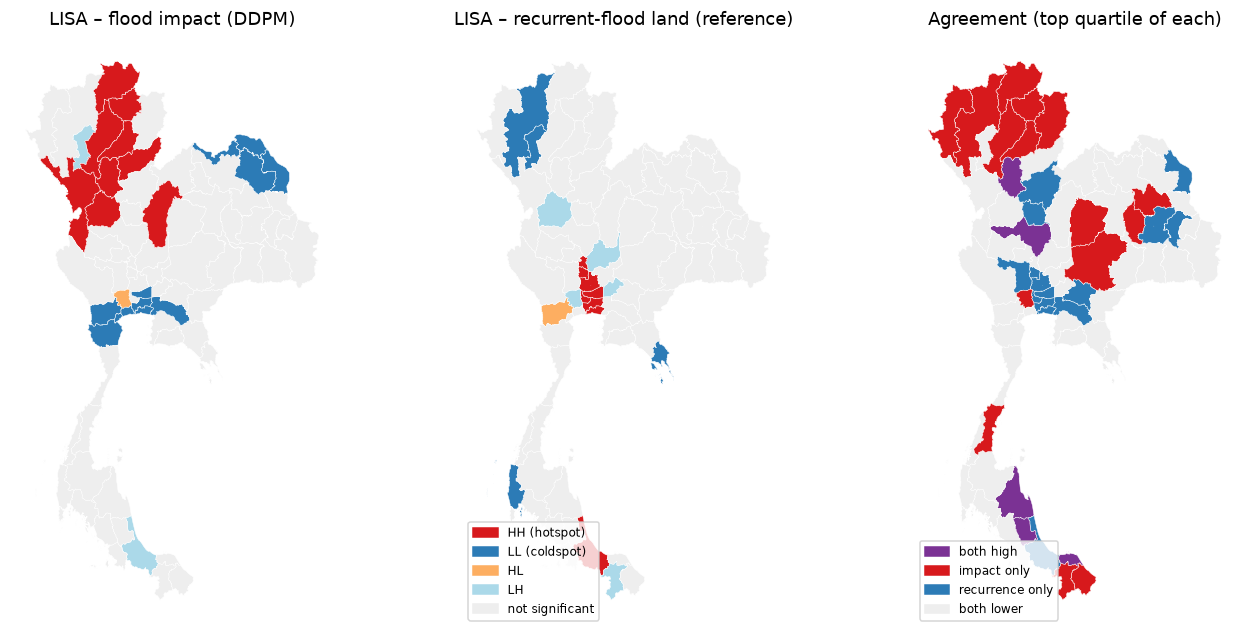

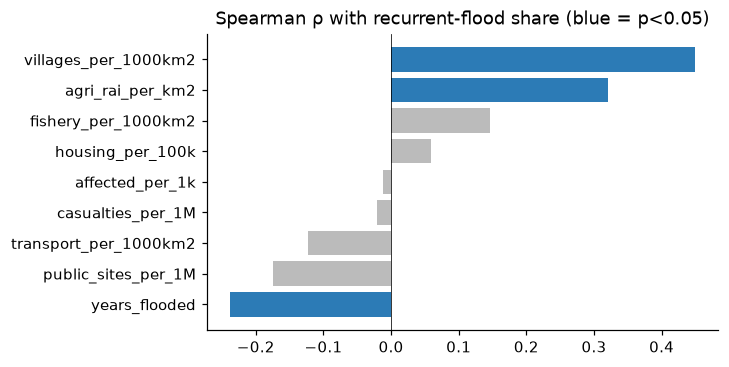

In [17]:
feat_rho = pd.DataFrame({c: stats.spearmanr(pf["f_" + c], ref) for c in FEATURES}, index=["rho", "p"]).T
feat_rho = feat_rho.sort_values("rho", ascending=False)
print(feat_rho.round(3))
RESULTS["feature_vs_ref_spearman"] = feat_rho.round(3).reset_index().to_dict(orient="records")

lisa_ref = Moran_Local(np.log1p(1000 * ref.values), w, permutations=9999, seed=SEED)
mi_ref = Moran(np.log1p(1000 * ref.values), w, permutations=9999)
pf["lisa_ref"] = [quad[q] if p < 0.05 else "not significant" for q, p in zip(lisa_ref.q, lisa_ref.p_sim)]
RESULTS["moran_ref"] = {"I": round(float(mi_ref.I), 3), "p": float(mi_ref.p_sim)}
RESULTS["lisa_ref_hotspots"] = pf.loc[pf.lisa_ref == "HH (hotspot)", "pro_en"].tolist()
print(f"Moran's I of reference map = {mi_ref.I:.3f} (p = {mi_ref.p_sim:.4f})")
print("Reference hotspots:", ", ".join(RESULTS["lisa_ref_hotspots"]))

# 2 x 2 agreement: high impact (severity top quartile) vs high recurrence (reference top quartile)
hi_imp = pf.severity_index >= pf.severity_index.quantile(.75)
cat = np.select([hi_imp & (pf.ref_high == 1), hi_imp & (pf.ref_high == 0), ~hi_imp & (pf.ref_high == 1)],
                ["both high", "impact only", "recurrence only"], "both lower")
pf["agreement"] = cat
ct = pd.crosstab(hi_imp.map({True: "impact top-25%", False: "impact rest"}),
                 pf.ref_high.map({1: "recurrence top-25%", 0: "recurrence rest"}))
print(ct)
RESULTS["agreement_counts"] = pd.Series(cat).value_counts().to_dict()
for c in ["both high", "impact only", "recurrence only"]:
    RESULTS[f"agreement_{c.replace(' ', '_')}"] = pf.loc[pf.agreement == c, "pro_en"].tolist()
    print(f"{c}: {', '.join(RESULTS[f'agreement_{c.replace(chr(32), chr(95))}'])}")

acol = {"both high": "#7b3294", "impact only": "#d7191c", "recurrence only": "#2c7bb6", "both lower": "#eeeeee"}
fig, ax = plt.subplots(1, 3, figsize=(15, 7))
geo.plot(color=pf["lisa"].map(lcol), ax=ax[0], edgecolor="white", lw=.3)
ax[0].set_title("LISA – flood impact (DDPM)")
geo.plot(color=pf["lisa_ref"].map(lcol), ax=ax[1], edgecolor="white", lw=.3)
ax[1].set_title("LISA – recurrent-flood land (reference)")
ax[1].legend(handles=[Patch(color=v, label=k) for k, v in lcol.items()], loc="lower left", fontsize=8)
geo.plot(color=pf["agreement"].map(acol), ax=ax[2], edgecolor="white", lw=.3)
ax[2].legend(handles=[Patch(color=v, label=k) for k, v in acol.items()], loc="lower left", fontsize=8)
ax[2].set_title("Agreement (top quartile of each)")
for a in ax:
    a.set_axis_off()
save("mismatch")

plt.figure(figsize=(6, 3.5))
plt.barh(feat_rho.index[::-1], feat_rho.rho[::-1],
         color=["#2c7bb6" if p < .05 else "#bbbbbb" for p in feat_rho.p[::-1]])
plt.axvline(0, c="k", lw=.5)
plt.title("Spearman ρ with recurrent-flood share (blue = p<0.05)")
save("feature_vs_ref")

## 7. Save results

In [18]:
pf.reset_index().to_csv(PROC / "province_results.csv", index=False)
(PROC / "results.json").write_text(json.dumps(RESULTS, indent=1, ensure_ascii=False, default=float))
print(json.dumps(RESULTS, indent=1, ensure_ascii=False, default=float)[:3000])

{
 "eda_raw_attributes": 48,
 "eda_median_skew": 5.34,
 "eda_skew_gt2": 43,
 "eda_median_zero_share": 0.82,
 "skew_raw_median": 2.88,
 "skew_log_median": 0.09,
 "pca_n_components": 5,
 "pca_cum_var": 0.849,
 "pca_pc1_var": 0.449,
 "kmeans_k_best_silhouette": 2,
 "kmeans_k_used": 4,
 "kmeans_seed_stability_ari": 0.8,
 "kmeans_table": [
  {
   "k": 2,
   "wcss": 390.512,
   "silhouette": 0.307,
   "davies_bouldin": 1.229,
   "smallest_cluster": 24,
   "seed_stability_ari": 0.981
  },
  {
   "k": 3,
   "wcss": 317.955,
   "silhouette": 0.217,
   "davies_bouldin": 1.433,
   "smallest_cluster": 14,
   "seed_stability_ari": 0.886
  },
  {
   "k": 4,
   "wcss": 272.631,
   "silhouette": 0.223,
   "davies_bouldin": 1.323,
   "smallest_cluster": 10,
   "seed_stability_ari": 0.8
  },
  {
   "k": 5,
   "wcss": 243.916,
   "silhouette": 0.2,
   "davies_bouldin": 1.325,
   "smallest_cluster": 4,
   "seed_stability_ari": 0.633
  },
  {
   "k": 6,
   "wcss": 213.764,
   "silhouette": 0.226,
   "davie